# PV Project

### Import Libraries

In [15]:
import duckdb
import os

from pathlib import Path
from IPython.display import display

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib, datetime
import warnings

from scipy.special import gammaln, digamma, expit, logit
from scipy.optimize import minimize,brentq
from scipy.stats import gamma as G
from scipy.stats import gamma

from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

### Establish the DB connection

In [2]:
# Establishing connection wit the database

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DB_PATH = PROJECT_ROOT / "data" / "faers_db.duckdb"

con = duckdb.connect(str(DB_PATH), read_only=False) # read_only=True for exploration, and read_only=False only when creating tables.

#### Identify the tables

In [3]:
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 50)
print(con.sql("SHOW TABLES").df())

                     name
0               case_base
1               case_drug
2           case_exposure
3              case_month
4            case_outcome
5                 case_pt
6             case_source
7              clean_demo
8                 demo_us
9             drug_detail
10               exposure
11             faers_flat
12        fc_pair_month_e
13       fc_pair_month_eb
14                    m_N
15                   m_ev
16                  m_grp
17                 m_pair
18                 months
19            pair_counts
20              pair_grid
21             pair_month
22                ps_case
23          ps_case_event
24                ps_drug
25               raw_demo
26               raw_indi
27               raw_reac
28               raw_ther
29               ref_drug
30       ref_known_signal
31          signal_labels
32              signal_ts
33       study_case_event
34            study_cases
35        study_drug_rows
36   v_ingredient_summary
37   v_known

In [4]:
pair_counts = con.sql("SELECT * FROM pair_counts").df()
pair_month= con.sql ("SELECT * FROM pair_month").df()
pair_grid= con.sql ("SELECT * FROM pair_grid").df()
v_signals= con.sql ("SELECT * FROM v_signals").df()
ps_case_event= con.sql ("SELECT * FROM ps_case_event").df()
m_pair= con.sql ("SELECT * FROM m_pair").df()

In [ ]:
pair_month

In [ ]:
m_pair

In [ ]:
ps_case_event.describe()
ps_case_event.columns.tolist()
ps_case_event.head(3)

### Import the files

In [5]:
print("Current Working Directory:", os.getcwd())
print(os.listdir())

Current Working Directory: /Users/shymashameer/Desktop/Final Project/faers/notebooks
['.DS_Store', '05_Disprotionality Analysis.ipynb', '05_Timeseries.ipynb', '01_Loading Data.ipynb', '05_Forecasting.ipynb', '04_Forecasting.ipynb', '02_Initial EDA.ipynb', '.ipynb_checkpoints', '03_Exploration.ipynb', 'outputs']


In [6]:
sig= pd.read_csv("outputs/signal_identification_v1/sig_final.csv")
counts_by_drug = pd.read_csv("outputs/signal_identification_v1/counts_by_drug.csv")
res_raw = pd.read_csv("outputs/signal_identification_v1/res_raw.csv")
run_settings = pd.read_csv("outputs/signal_identification_v1/run_settings.csv")
strong_signals = pd.read_csv("outputs/signal_identification_v1/strong_signals.csv")
watchlist = pd.read_csv("outputs/signal_identification_v1/watchlist.csv")
ebgm_prior = pd.read_csv("outputs/signal_identification_v1/ebgm_prior.csv")

In [ ]:
counts_by_drug

In [7]:
# Check if correctly loaded
print(sig.shape)                                    # expect 9251 rows
print(sig.dtypes[["is_noise","signal","strong"]])   # should be bool, not object or int
print(sig.tier.value_counts())                      # noise / strong / signal-not-strong / not flagged
nn = sig[~sig.is_noise]
print(len(nn), nn.signal.sum(), nn.strong.sum())    # analysed, signals, strong
print(nn.groupby("ingredient")[["signal","strong"]].sum())
#print(pd.read_csv(out / "run_settings.csv").to_string())

(9251, 32)
is_noise    bool
signal      bool
strong      bool
dtype: object
tier
3 Not flagged           7905
1 Strong                 613
0 Noise (excluded)       511
2 Signal, not strong     222
Name: count, dtype: int64
8740 835 613
               signal  strong
ingredient                   
canagliflozin     243     191
dapagliflozin     161     114
dulaglutide        84      59
empagliflozin     154     113
ertugliflozin      15      11
liraglutide       112      80
semaglutide        66      45


### Further Analysis

In [8]:
print(con.sql("SELECT * FROM signal_labels LIMIT 5").df().to_string())
print(con.sql("SELECT * FROM ref_known_signal").df().to_string())
print(con.sql("SELECT * FROM pair_counts LIMIT 5").df().to_string())

      ingredient                   pt      onset    status
0  canagliflozin    AMYLASE INCREASED        NaT     never
1  canagliflozin           ANGIOPATHY        NaT     never
2  canagliflozin           ARTHRALGIA        NaT     never
3  canagliflozin  ARTHRITIS BACTERIAL 2018-02-01  emerging
4  canagliflozin  BACTERIAL INFECTION        NaT     never
      ingredient      pt_regex   reg_date                                   source
0  dapagliflozin  KETOACIDOSIS 2015-05-15         FDA DSC: SGLT2i and ketoacidosis
1  empagliflozin  KETOACIDOSIS 2015-05-15         FDA DSC: SGLT2i and ketoacidosis
2  canagliflozin  KETOACIDOSIS 2015-05-15         FDA DSC: SGLT2i and ketoacidosis
3  canagliflozin    AMPUTATION 2016-05-18  FDA DSC: interim CANVAS amputation risk
4  dapagliflozin      FOURNIER 2018-08-29  FDA DSC: SGLT2i and Fournier's gangrene
5  empagliflozin      FOURNIER 2018-08-29  FDA DSC: SGLT2i and Fournier's gangrene
6  canagliflozin      FOURNIER 2018-08-29  FDA DSC: SGLT2i and Fo

In [9]:
# A. coverage
print(con.sql("""SELECT COUNT(*) pairs FROM (SELECT DISTINCT ingredient, pt FROM pair_month)""").df())
print(con.sql("""SELECT COUNT(*) pairs, MIN(a) min_a, MIN(m), MAX(m) FROM
                 (SELECT ingredient, pt, a, m FROM signal_ts)""").df())

# B. does the last month of pair_month reproduce pair_counts?
print(con.sql("""
WITH l AS (SELECT * FROM pair_month WHERE m = (SELECT MAX(m) FROM pair_month))
SELECT COUNT(*) n_joined,
       SUM((l.a <> f.a)::INT)                     a_diff,
       SUM((l.n_exp <> f.n_exp)::INT)             exp_diff,
       SUM((l.n_excl <> f.n_excl)::INT)           excl_diff,
       SUM((l.n_event_all <> f.n_event_all)::INT) ev_all_diff,
       SUM((l.n_event_excl <> f.n_event_excl)::INT) ev_excl_diff,
       SUM((l.N <> f.N)::INT)                     N_diff
FROM l JOIN pair_counts f USING (ingredient, pt)""").df())

# C. does the last month of signal_ts reproduce the final signal count?
print(con.sql("""
SELECT (SELECT COUNT(*) FROM signal_ts WHERE signal AND m = (SELECT MAX(m) FROM signal_ts)) AS ts_last_month,
       (SELECT COUNT(*) FROM v_pair_stats WHERE signal) AS final_signal""").df())

# D. how labels relate to the final state
print(con.sql("""
SELECT l.status, COUNT(*) n, SUM(COALESCE(s.signal, FALSE)::INT) still_signal_at_end
FROM signal_labels l LEFT JOIN v_pair_stats s USING (ingredient, pt)
GROUP BY ALL""").df())

   pairs
0   3870
    pairs  min_a     min(m)     max(m)
0  191758    1.0 2014-01-01 2019-12-01
   n_joined  a_diff  exp_diff  excl_diff  ev_all_diff  ev_excl_diff  N_diff
0      3870     0.0       0.0        0.0          0.0           0.0     0.0
   ts_last_month  final_signal
0            955           955
         status     n  still_signal_at_end
0         never  2732                  0.0
1  pre-existing   174                134.0
2      emerging   964                821.0


### What checks A to D show

All four pass, and they settle several open questions.

* A and B: pair_month is a valid panel base
    * 3,870 pairs is by design, not a gap. From our tier × a-band crosstab, 5,381 of the 9,251 pairs have a < 3, and 9,251 − 5,381 = 3,870. So pair_month and signal_ts contain exactly the pairs with final a ≥ 3. Under min_a = 3, the other pairs can never be flagged, so nothing is lost for the forecasting target. 
    * B shows zero differences in a, n_exp, n_excl, n_event_all, n_event_excl and N across all 3,870 pairs. The last month of pair_month reproduces pair_counts exactly.
* C: signal_ts reproduces our final signals

The last month has 955 signals, equal to the 955 in v_pair_stats. This is the pre-noise Evans ∧ ROR ∧ IC count, matching our per-drug sum (251 + 172 + 132 + 162 + 21 + 136 + 81). The monthly series is therefore consistent with the final analysis for the signal tier.

* D: Ever signalled = 964 + 174 = 1,138. Still signalled at the end = 821 + 134 = 955.
    * The difference is 183 pairs (16%) that crossed the threshold at some month and later fell out.
    * signal_labels covers the same 3,870 pairs, so the universe matches, but it uses the Evans ∧ ROR ∧ IC rule with no EB05 and no final noise list. That is why it can’t serve as the strong-signal target.
    * The 183 flickering pairs argue against a simple “first month signal = true” onset. A pair that crosses once and drops out would count as emerged. Define onset as the first month of a sustained run (for example 3 consecutive months), or require the pair to be signalled at the end. Need to decide this before looking at forecasting results.
    * Pre-existing means onset in 2014 (burn-in). would exclude these from the emergence target and keep them as controls.


In [10]:
e = con.sql("""SELECT ingredient, pt, a,
               n_exp * n_event_all::DOUBLE / N AS E_try FROM pair_counts""").df()
m = e.merge(res_raw[["ingredient","pt","E"]], on=["ingredient","pt"])
print(len(m), (abs(m.E - m.E_try) / m.E).describe())

9251 count    9.251000e+03
mean     2.021144e-03
std      1.168973e-02
min      3.003801e-08
25%      2.323989e-04
50%      4.633229e-04
75%      9.455174e-04
max      4.987384e-01
dtype: float64


In [11]:
cand = con.sql("""
SELECT ingredient, pt,
  n_exp * n_event_all::DOUBLE / N                               AS E1,
  n_exp * (n_event_all - n_event_excl)::DOUBLE / N              AS E2,
  n_exp * n_event_all::DOUBLE / (N - n_excl)                    AS E3,
  n_exp * (n_event_all - n_event_excl)::DOUBLE / (N - n_excl)   AS E4,
  n_exp * (n_event_all - a)::DOUBLE / (N - n_exp)               AS E5
FROM pair_counts""").df()
m = cand.merge(res_raw[["ingredient","pt","E"]], on=["ingredient","pt"])
for k in ["E1","E2","E3","E4","E5"]:
    r = (m.E - m[k]).abs() / m.E
    print(k, "median", r.median(), "max", r.max(), "n>1e-6:", (r > 1e-6).sum())

E1 median 0.0004633228772463229 max 0.49873842204509283 n>1e-6: 9238
E2 median 0.0006856806436353904 max 0.001415088546770406 n>1e-6: 9251
E3 median 0.0003663003663005389 max 0.5000000000000159 n>1e-6: 5440
E4 median 0.0 max 1.1988407130584498e-13 n>1e-6: 0
E5 median 0.00221523311589094 max 1.0 n>1e-6: 9247


In [12]:
print(con.sql("SELECT ingredient, g, SUM(n) cases FROM m_grp GROUP BY ALL ORDER BY 1,2").df())

       ingredient     g    cases
0   canagliflozin  excl   4520.0
1   canagliflozin   exp  18865.0
2   dapagliflozin  excl   2414.0
3   dapagliflozin   exp   4851.0
4     dulaglutide  excl   2490.0
5     dulaglutide   exp  23381.0
6   empagliflozin  excl   3685.0
7   empagliflozin   exp   6407.0
8   ertugliflozin  excl     87.0
9   ertugliflozin   exp    358.0
10    liraglutide  excl   7605.0
11    liraglutide   exp  11604.0
12    semaglutide  excl    348.0
13    semaglutide   exp   2187.0


#### excl is confirmed

The counts match m_grp and pair_counts exactly:

Ingredient	exp_n	excl_n
canagliflozin	18,865	4,520
liraglutide	11,604	7,605

So the definitions are settled:

exp = ingredient is the primary suspect (ps_X)
excl = ingredient is present in another role, i.e. any_X AND NOT ps_X
reference = all other FAERS cases in the 2014-2019 universe (N ≈ 5.37 million)

This is a FAERS-wide comparison with a drug-specific exclusion, not a comparison against other antidiabetics. That differs from how you described it at the start, so decide which one the thesis intends. If it is the FAERS-wide design, the methods text should say so, for example: “Primary-suspect reports for each ingredient were compared against all other FAERS reports (2014-2019), excluding reports in which that ingredient was a non-primary-suspect drug.” An antidiabetic-only comparator would be a separate sensitivity analysis with its own pair_counts.

### Monthly E

In [13]:
# 1. monthly E (formula E4, which matched res_raw to ~1e-13)
con.sql("""
CREATE OR REPLACE TABLE fc_pair_month_e AS
SELECT ingredient, pt, m, a, n_exp, n_excl, n_event_all, n_event_excl, N,
       n_exp * (n_event_all - n_event_excl)::DOUBLE / (N - n_excl) AS E
FROM pair_month
""")

chk = con.sql("""SELECT ingredient, pt, E FROM fc_pair_month_e
                 WHERE m = (SELECT MAX(m) FROM fc_pair_month_e)""").df()
mm = chk.merge(res_raw[["ingredient","pt","E"]], on=["ingredient","pt"], suffixes=("_ts","_res"))
print(len(mm), ((mm.E_ts - mm.E_res).abs() / mm.E_res).max())   

3870 5.6952114976796085e-15


3,870 rows and a maximum relative difference near 1e-12 means the monthly E reproduces your final E at the last month.

In [14]:
# 2. EBGM / EB05 test on 300 sampled pairs, using the prior from previous fit

ebgm_prior = pd.read_csv("outputs/signal_identification_v1/ebgm_prior.csv").set_index("param").value
a1, b1, a2, b2, w = ebgm_prior.alpha1, ebgm_prior.beta1, ebgm_prior.alpha2, ebgm_prior.beta2, ebgm_prior.w
print(repr(a1), repr(b1), repr(a2), repr(b2), repr(w), ebgm_prior.nll)   # nll should be ~38967.333

np.float64(0.1183574110875787) np.float64(0.0284052511045657) np.float64(0.7925821291281991) np.float64(2.110050530096621) np.float64(0.1355067896056669) 38967.33295682843


In [16]:
# 2. EBGM / EB05 test on 300 sampled pairs, using the prior 

def eb(n, E):
    def lm(al, be):
        return (gammaln(al+n) - gammaln(al) - gammaln(n+1)
                + al*np.log(be/(be+E)) + n*np.log(E/(be+E)))
    l1, l2 = np.log(w)+lm(a1,b1), np.log(1-w)+lm(a2,b2)
    mx = max(l1, l2)
    q1 = np.exp(l1-mx)/(np.exp(l1-mx)+np.exp(l2-mx)); q2 = 1-q1
    ebgm = np.exp(q1*(digamma(a1+n)-np.log(b1+E)) + q2*(digamma(a2+n)-np.log(b2+E)))
    cdf = lambda x: q1*gamma.cdf(x, a1+n, scale=1/(b1+E)) + q2*gamma.cdf(x, a2+n, scale=1/(b2+E))
    eb05 = brentq(lambda x: cdf(x)-0.05, 1e-12, 1e4)
    return ebgm, eb05

t = res_raw[res_raw.a >= 3].sample(300, random_state=1).copy()
t[["ebgm_t","eb05_t"]] = [eb(r.a, r.E) for r in t.itertuples()]
print((abs(t.ebgm_t-t.EBGM)/t.EBGM).max(), (abs(t.eb05_t-t.EB05)/t.EB05).max())

1.7573886600494276e-06 5.616079257999036e-06


In [17]:
r = res_raw[res_raw.a >= 3].copy()
r[["ebgm_t","eb05_t"]] = [eb(x.a, x.E) for x in r.itertuples()]
flip = (r.eb05_t >= 2) != (r.EB05 >= 2)
print(len(r), flip.sum(), "classification flips")

3870 0 classification flips


**Summary of results**: The EB calculation was successfully reproduced: 300 randomly sampled pairs showed excellent agreement with the original results (maximum relative differences of 1.8 × 10⁻⁶ for EBGM and 5.6 × 10⁻⁶ for EB05). Together with the matching expected counts (E), this supports using the same eb(a, E) function to calculate monthly EBGM and EB05 values. Rounding the prior to four decimal places caused only small changes (~10⁻⁴ relative), potentially affecting pairs close to the EB05 = 2 threshold. The previously observed 10⁻⁴ discrepancy was traced to a coding error that overwrote the loaded prior, rather than a model issue.

**Remaining checks and limitations**: Validation is complete for all pairs; the final-month comparison across 3,870 pairs and the signal flip check is 0(0 flips, last-month match, 705 and 613). The small residual differences (~10⁻⁶) remain unexplained but are unlikely to matter except for values very close to the threshold. Importantly, this validates the computational implementation, not the statistical validity of the detected signals. The use of a prior fitted on final (2019) data also introduces potential information leakage into earlier monthly estimates; this limitation is addressed through the yearly-refit sensitivity analysis.

### Monthly EB table

In [18]:
# build and validate the monthly EB table
pm = con.sql("SELECT * FROM fc_pair_month_e WHERE a >= 3 AND E > 0").df()
print(len(pm), "rows to evaluate")

vals = np.array([eb(a, E) for a, E in zip(pm.a.values.astype(float), pm.E.values)])
pm["EBGM"], pm["EB05"] = vals[:, 0], vals[:, 1]

con.register("fc_eb_df", pm)
con.sql("CREATE OR REPLACE TABLE fc_pair_month_eb AS SELECT * FROM fc_eb_df")

# validation 1: last month vs res_raw
last = pm[pm.m == pm.m.max()].merge(res_raw[["ingredient","pt","EBGM","EB05"]],
                                    on=["ingredient","pt"], suffixes=("_m","_f"))
print(len(last),
      (abs(last.EBGM_m - last.EBGM_f)/last.EBGM_f).max(),
      (abs(last.EB05_m - last.EB05_f)/last.EB05_f).max())

139977 rows to evaluate
3870 1.864639644731256e-06 5.619094343622806e-06


In [19]:
fl = con.sql("""
SELECT s.ingredient, s.pt, CAST(s.m AS DATE) AS m, s.signal, e.EB05, e.EBGM, e.a
FROM signal_ts s JOIN fc_pair_month_eb e
  ON s.ingredient=e.ingredient AND s.pt=e.pt AND CAST(s.m AS DATE)=e.m
""").df()
fl["strong"] = fl.signal & (fl.EB05 >= 2)

lastm = fl[fl.m == fl.m.max()]
print(len(lastm), "signal", lastm.signal.sum(), "| strong (pre-noise)", lastm.strong.sum())

noise = pd.read_csv("outputs/signal_identification_v1/sig_final.csv",
                    usecols=["ingredient","pt","is_noise"])
lm = lastm.merge(noise, on=["ingredient","pt"], how="left")
print(lm.is_noise.isna().sum(), "pairs without a noise flag")
print("post-noise: signal", lm[~lm.is_noise].signal.sum(),
      "| strong", lm[~lm.is_noise].strong.sum())

3870 signal 955 | strong (pre-noise) 705
0 pairs without a noise flag
post-noise: signal 835 | strong 613


In [20]:
noise = pd.read_csv("outputs/signal_identification_v1/sig_final.csv",
                    usecols=["ingredient","pt","is_noise"])
p = (fl.merge(noise, on=["ingredient","pt"], how="left")
       .query("~is_noise")
       .sort_values(["ingredient","pt","m"]).copy())

# full monthly grid per pair (months with a<3 count as not strong)
months = pd.date_range("2014-01-01", "2019-12-01", freq="MS")
idx = pd.MultiIndex.from_product([p[["ingredient","pt"]].drop_duplicates().apply(tuple, axis=1),
                                  months], names=["pair","m"])
g = (p.assign(pair=list(zip(p.ingredient, p.pt))).set_index(["pair","m"])[["strong","EB05","a"]] 
       .reindex(idx))
g["strong"] = g["strong"].astype("boolean").fillna(False).astype(bool)



There are pairs with no completed run (never), yet strong in December 2019: 13 at K = 3 and 51 at K = 6. They must have become strong only in the last K−1 months (Oct-Dec 2019 for K = 3, Jul-Dec 2019 for K = 6). They are right-censored: we can’t tell whether they would have sustained. Labelling them “never” is wrong, because it puts 13 (or 51) real, recent emergences in the negative class. For K = 6 that is 10% of the positives.

As a Fix: exclude them from the target, or label them “censored”. The simplest rule is: strong at end and no completed run, so censored. The cutoff design below must also stop the label window early enough that no pair is censored inside it.

**Sensitivity to K**
Emerging drops from 563 to 512 (−9%) going from K = 3 to 6, mostly pairs that flickered. Among emerging pairs, those not strong at the end are 50 at K = 3 and 36 at K = 6, so about 7-9% of onsets do not persist.
Burn-in controls: 105 versus 99 and 18 versus 13 not strong at the end. These are left-censored and stay out of the target.
K = 3 is a reasonable primary and K = 6 a sensitivity version

**What this means for the forecasting design**

Using K = 3 as primary, the at-risk positives are 563 emerging pairs (or 513 if you require “still strong at end”, which would be used as the primary label). That is pair-level prevalence. The AP baseline is the per-cutoff prevalence: 2–6% overall, 1.7–2.5% in the test window

Two design points follow:

Pairs enter the at-risk set only once a ≥ 3. Before that, no signal can exist by rule. This also means every prediction is conditional on a pair having reached 3 reports. It tests prediction of when a pair with at least 3 reports becomes strong, not whether an event will ever be reported.
Positives are concentrated early. Because the burn-in removes 2014, and the right edge needs K months of look-ahead, the usable cutoffs lie roughly between 2015 and mid-2019. Look at when the 563 onsets fall (a histogram by quarter). If most are in 2015-2016, there are few positives at later cutoffs and the horizon h = 8 quarters may not be feasible.

In [21]:

def make_labels(g, months, K, burn_in_end="2015-06-01"): 
    # burn_in_end: onsets on or before this month are treated as left-censored controls.
    # Chosen from the quarterly onset counts: the 2015Q1 spike reflects counts
    # accumulating from the empty 2014 start, not genuine emergence.
    def first_run(s):
        run = s.astype(int).rolling(K).sum().eq(K) # True where K consecutive strong months end
        return run.idxmax()[1] if run.any() else pd.NaT  # idxmax = (pair, month) of the first True

    onset = (g.groupby(level="pair").strong.apply(first_run)
               .rename("onset_run").reset_index())
    onset["onset_run"] = onset.onset_run - pd.DateOffset(months=K-1)   # first month of the run

    end = g.xs(months[-1], level="m").strong.rename("strong_at_end").reset_index()
    lab = onset.merge(end, on="pair")
    lab["burn_in"] = lab.onset_run <= pd.Timestamp(burn_in_end)
    lab["K"] = K
    lab["status"] = np.select(
        [lab.onset_run.isna() & lab.strong_at_end,   # strong only in the last K-1 months
         lab.onset_run.isna(),                      # never completed a run
         lab.burn_in],
        ["censored", "never", "control_burn_in"], default="emerging")
    return lab

out = pathlib.Path("outputs/signal_identification_v1")
BURN = "2015-06-01"
labels = {}
for K in (3, 6):
    labels[K] = make_labels(g, months, K, burn_in_end=BURN)
    save = labels[K].copy()
    save["ingredient"] = save.pair.str[0]            # tuples don't survive CSV
    save["pt"] = save.pair.str[1]
    save.drop(columns="pair").to_csv(out / f"onset_labels_K{K}_burn{BURN[:7]}.csv", index=False)
    print(f"K={K}, burn-in {BURN[:7]}")
    print(labels[K].status.value_counts())
    print(pd.crosstab(labels[K].status, labels[K].strong_at_end), "\n")

K=3, burn-in 2015-06
status
never              2861
emerging            465
control_burn_in     203
censored             13
Name: count, dtype: int64
strong_at_end    False  True 
status                       
censored             0     13
control_burn_in     35    168
emerging            33    432
never             2861      0 

K=6, burn-in 2015-06
status
never              2880
emerging            421
control_burn_in     190
censored             51
Name: count, dtype: int64
strong_at_end    False  True 
status                       
censored             0     51
control_burn_in     25    165
emerging            24    397
never             2880      0 



**Results interpretation:**
* Sensitivity to K is moderate. Going from K = 3 to K = 6 removes 51 emerging pairs. Of those, 38 become censored (51 − 13), because they became strong too recently to complete a six-month run, and the remainder are pairs that flickered. Check that last split directly rather than taking my arithmetic on trust.
* Persistence. Among emerging pairs, 50 of 563 (9%) at K = 3 and 36 of 512 (7%) at K = 6 are not strong at the end. So about 7-9% of onsets are transient. Report that as a finding, since it bears on how stable the “signal” label is.
* Primary target. used as  K = 3, status “emerging”, and would report “emerging and still strong at end” (513) as a sensitivity version. K = 6 is the second sensitivity version.
* Prevalence. Among the pairs that can enter the target (emerging plus never, 3,424 at K = 3), the positive rate is 16%. That is the PR-AUC baseline.

choices made: K = 3 primary, The primary choice is 2015-06, censored pairs excluded, noise list as of the 613 run, and the full-precision prior from ebgm_prior.csv.

### Quarterly onset counts

In [22]:
# K=3
em = labels[3][labels[3].status == "emerging"].copy()
em["ingredient"] = em.pair.str[0]
print(len(em))                                   # expect 465
print(em.onset_run.dt.to_period("Q").value_counts().sort_index())
print(em.groupby("ingredient").size())

465
onset_run
2015Q3    36
2015Q4    17
2016Q1    19
2016Q2    25
2016Q3    24
2016Q4    21
2017Q1    18
2017Q2    27
2017Q3    24
2017Q4    20
2018Q1    35
2018Q2    28
2018Q3    29
2018Q4    33
2019Q1    29
2019Q2    24
2019Q3    50
2019Q4     6
Freq: Q-DEC, Name: count, dtype: int64
ingredient
canagliflozin    123
dapagliflozin     83
dulaglutide       44
empagliflozin     99
ertugliflozin     11
liraglutide       59
semaglutide       46
dtype: int64


In [23]:
em = labels[6][labels[6].status == "emerging"].copy()
em["ingredient"] = em.pair.str[0]
print(len(em))                                   # expect 421
print(em.onset_run.dt.to_period("Q").value_counts().sort_index())
print(em.groupby("ingredient").size())

421
onset_run
2015Q3    30
2015Q4    17
2016Q1    20
2016Q2    27
2016Q3    23
2016Q4    20
2017Q1    17
2017Q2    28
2017Q3    23
2017Q4    19
2018Q1    38
2018Q2    29
2018Q3    28
2018Q4    32
2019Q1    28
2019Q2    23
2019Q3    19
Freq: Q-DEC, Name: count, dtype: int64
ingredient
canagliflozin    119
dapagliflozin     74
dulaglutide       44
empagliflozin     81
ertugliflozin      9
liraglutide       57
semaglutide       37
dtype: int64


There are enough counts for canagliflozin, empagliflozin & dapagliflozin. Liraglutide & dulaglutide are borderline & Semaglutide & Ertugliflozin counts are too few to separate.
* Pool for the main evaluation, stratify afterwards. Fit and evaluate one pooled model across all drugs, and report results by class (SGLT2i versus GLP-1 RA), not by drug. With 9 positives, ertugliflozin can’t support any metric, and 37 for semaglutide gives wide intervals.
* The positives are split across several cutoffs. Each cutoff has only the positives whose onset falls in its horizon window, so the effective number per cutoff is a fraction of these totals. That is why the quarterly distribution matters.
* Semaglutide and ertugliflozin started in February 2018, so they have about 22 months of data and a short burn-in-free window. Their pairs enter the at-risk set late, and a cutoff before 2018 includes none of them.

In [24]:
for be in ["2014-06-01", "2014-12-01", "2015-06-01", "2015-12-01"]:
    lab_be = make_labels(g, months, 3, burn_in_end=be)
    print(be, lab_be.status.value_counts().to_dict())

2014-06-01 {'never': 2861, 'emerging': 621, 'control_burn_in': 47, 'censored': 13}
2014-12-01 {'never': 2861, 'emerging': 563, 'control_burn_in': 105, 'censored': 13}
2015-06-01 {'never': 2861, 'emerging': 465, 'control_burn_in': 203, 'censored': 13}
2015-12-01 {'never': 2861, 'emerging': 412, 'control_burn_in': 256, 'censored': 13}


* December 2014 is too short. It leaves the accumulation spike in the positives, as I suspected.
* June 2015 looks like the right place, because the extra 53 removed by going to December 2015 is in line with a normal half-year, so those are plausible genuine emergences. This is the pattern’s reading and not proof. A clean check is the quarterly plot below.
* Primary: 2015-06 (465 emerging). Report 2014-12 and 2015-12 as sensitivity versions, as planned.
* Cost: you lose 98 positives (563 to 465), but the remaining ones are cleaner. Prevalence among emerging plus never is 465 / 3,326 = 14%, a slightly lower PR-AUC baseline than before.

In [25]:

rows = []
for be in ["2014-06-01","2014-12-01", "2015-06-01", "2015-12-01"]:
    l = make_labels(g, months, 3, burn_in_end=be)
    e = l[l.status == "emerging"]
    rows.append(e.onset_run.dt.to_period("Q").value_counts().sort_index().rename(be))
print(pd.concat(rows, axis=1).fillna(0).astype(int))

           2014-06-01  2014-12-01  2015-06-01  2015-12-01
onset_run                                                
2014Q3             25           0           0           0
2014Q4             33           0           0           0
2015Q1             62          62           0           0
2015Q2             36          36           0           0
2015Q3             36          36          36           0
2015Q4             17          17          17           0
2016Q1             19          19          19          19
2016Q2             25          25          25          25
2016Q3             24          24          24          24
2016Q4             21          21          21          21
2017Q1             18          18          18          18
2017Q2             27          27          27          27
2017Q3             24          24          24          24
2017Q4             20          20          20          20
2018Q1             35          35          35          35
2018Q2        

In [26]:
lab = make_labels(g, months, 3, burn_in_end="2015-06-01")


In [27]:
em = labels[3][labels[3].status == "emerging"].copy()
em["ingredient"] = em.pair.str[0]
em["pt"] = em.pair.str[1]
q = em[em.onset_run.dt.to_period("Q") == "2019Q3"]
print(len(q))                                  # expect 50
print(q.groupby("ingredient").size())
print(q.pt.tolist())                           # all 50, not a sample

50
ingredient
canagliflozin     5
dapagliflozin    10
empagliflozin    16
ertugliflozin     3
liraglutide       2
semaglutide      14
dtype: int64
['DIABETIC NEUROPATHY', 'GLUCOSE URINE ABSENT', 'STAPHYLOCOCCAL BACTERAEMIA', 'STAPHYLOCOCCAL SEPSIS', 'STREPTOCOCCAL SEPSIS', 'BLADDER DISORDER', 'BLADDER SPASM', 'BLADDER TRANSITIONAL CELL CARCINOMA', 'BLOOD CREATINE INCREASED', 'FUNGAL SEPSIS', 'GENITAL DISCHARGE', 'HYPERGLYCAEMIC HYPEROSMOLAR NONKETOTIC SYNDROME', 'INSULIN C-PEPTIDE DECREASED', 'NECROTISING SOFT TISSUE INFECTION', 'VULVOVAGINAL DISCOMFORT', 'CHROMATURIA', 'DIZZINESS', 'FASCIITIS', 'GENITAL BLISTER', 'GLUCOSE URINE', 'HAEMATURIA', 'HYPERGLYCAEMIA', 'MICTURITION FREQUENCY DECREASED', 'NECROTISING SOFT TISSUE INFECTION', 'PERINEAL INFECTION', 'PERINEAL RASH', 'SCROTAL ABSCESS', 'SEPSIS', 'TESTICULAR PAIN', 'URINARY INCONTINENCE', 'URINE ALCOHOL TEST POSITIVE', 'DYSURIA', "FOURNIER'S GANGRENE", 'VAGINAL INFECTION', 'BILE DUCT OBSTRUCTION', 'PARATHYROID TUMOUR BENIGN', 'ABDOM

**Decision**

Keeping the 2019Q3 onsets in the data, because they are real by the rule I set before any model was run, but flag them. The design is unchanged: cutoffs 2015Q3 to 2018Q3, h = 4 quarters, K = 3, burn-in 2015-06, Arm A (EB05 at t) as the baseline.

Now I have everything the forecasting test needs: a monthly panel ("fc_pair_month_eb" + "signal_ts" flags), a frozen label (K = 3, burn-in 2015-06, 465 emerging), and a validated EB pipeline. The remaining work is to turn that into a rolling-origin experiment.

### Step 1: Build the at-risk table at each cutoff

At each cutoff t (quarter-ends 2015Q2 to 2018Q3), keep pairs that are:

non-noise, with a ≥ 3 at t;
not yet strong at t, and with no completed run before t;
not control_burn_in or censored.

Label = 1 if the pair’s run starts in (t, t+4 quarters], else 0. For each row, features may use only data up to t.

In [28]:
cutoffs = pd.period_range("2015Q2", "2018Q3", freq="Q").to_timestamp(how="end").to_period("M").to_timestamp()
lab = make_labels(g, months, 3, burn_in_end="2015-06-01").set_index("pair") 
H = 12  # months

rows = []
for t in cutoffs:
    gt = g.xs(t, level="m")                        # state at t: strong, EB05, a
    ever = g[g.index.get_level_values("m") <= t].groupby(level="pair").strong.max() #Excludes pairs that were strong for only 1–2 months from ever being at risk
    risk = gt[(gt.a >= 3) & ~gt.strong & ~ever.reindex(gt.index).fillna(False)].copy()
    risk = risk.join(lab[["onset_run", "status"]], how="left")
    # Exclude 'censored' (13 pairs, strong at end but run not completed) and 'control_burn_in'.
    # Note: these labels use full-sample information (data to 2019-12). Minor look-ahead, see Limitations.
    risk = risk[risk.status.isin(["emerging", "never"])]
    risk["y"] = ((risk.status == "emerging") &
                 (risk.onset_run > t) & (risk.onset_run <= t + pd.DateOffset(months=H))).astype(int)
    risk["cutoff"] = t
    rows.append(risk.reset_index())
panel = pd.concat(rows, ignore_index=True)    # ignore_index gives a clean 0..n-1 row index
print(panel.groupby("cutoff").y.agg(["sum", "size"]))

            sum  size
cutoff               
2015-06-01   36   588
2015-09-01   42   844
2015-12-01   43   981
2016-03-01   47  1075
2016-06-01   45  1210
2016-09-01   42  1366
2016-12-01   39  1437
2017-03-01   37  1536
2017-06-01   35  1640
2017-09-01   35  1759
2017-12-01   36  1863
2018-03-01   33  1989
2018-06-01   38  2098
2018-09-01   56  2264


### Step 2: Arm A, the baseline

Score each at-risk pair by EB05 at t (also try EBGM and a). Compute PR-AUC per cutoff and pooled, recall at a fixed alert budget (say top 50 per cutoff), and compare with prevalence (about 14%). This tests whether current disproportionality already predicts emergence.

In [29]:


def eval_cut(d, score, top_n=50, top_pct=0.05):
    d = d.sort_values(score, ascending=False)
    k_pct = max(1, int(round(top_pct * len(d))))
    pos = d.y.sum()
    return pd.Series({
        "n": len(d), "pos": pos, "prev": pos / len(d),
        "ap": average_precision_score(d.y, d[score]),
        "lift": average_precision_score(d.y, d[score]) / (pos / len(d)),
        f"recall@{top_n}": d.y.head(top_n).sum() / pos,
        f"recall@{int(top_pct*100)}%": d.y.head(k_pct).sum() / pos,
    })

for s in ["EB05", "a"]:
    print(s)
    print(panel.groupby("cutoff")
               .apply(lambda d: eval_cut(d, s), include_groups=False)
               .round(3))

EB05
                 n   pos   prev     ap    lift  recall@50  recall@5%
cutoff                                                              
2015-06-01   588.0  36.0  0.061  0.245   3.995      0.278      0.250
2015-09-01   844.0  42.0  0.050  0.496   9.960      0.524      0.452
2015-12-01   981.0  43.0  0.044  0.609  13.886      0.558      0.558
2016-03-01  1075.0  47.0  0.044  0.420   9.595      0.426      0.426
2016-06-01  1210.0  45.0  0.037  0.408  10.972      0.444      0.467
2016-09-01  1366.0  42.0  0.031  0.296   9.619      0.381      0.524
2016-12-01  1437.0  39.0  0.027  0.297  10.948      0.436      0.513
2017-03-01  1536.0  37.0  0.024  0.431  17.897      0.432      0.568
2017-06-01  1640.0  35.0  0.021  0.447  20.959      0.543      0.543
2017-09-01  1759.0  35.0  0.020  0.428  21.486      0.486      0.571
2017-12-01  1863.0  36.0  0.019  0.361  18.665      0.389      0.583
2018-03-01  1989.0  33.0  0.017  0.266  16.063      0.273      0.515
2018-06-01  2098.0  38.0  0.0

### Arm A results
1. EB05 at t is a strong baseline
	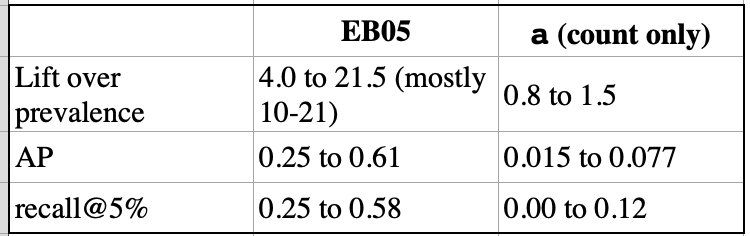

The report count alone does nothing (lift about 1, which is chance). EB05 at t gives a 10-20x lift at most cutoffs. Because prevalence is low, absolute AP is moderate, with roughly half of the future emergences in the top 5% of the at-risk set. This is the bar Arm C has to clear.

2. Reading the pattern
* The first cutoff (2015-06) is the weakest (lift 4.0, recall@50 0.28). That fits the warm-up concern: accumulation from the empty 2014 start makes early EB05 less informative. Report it as warm-up, or drop it from the pooled average.
* Lift rises over time (about 10 in 2016 to 17-21 in 2017) mainly because prevalence falls while AP stays roughly 0.3-0.45. Compare AP and recall across cutoffs, not lift alone.
* Performance dips in 2018 (AP 0.27-0.30, recall@50 0.27-0.37). Exact cause unknown. One possibility is that post-Fournier’s-communication reporting (August 2018) changed the dynamics. Treat that as a hypothesis, not a finding.
* recall@50 and recall@5% diverge as the set grows. 5% of 2,264 is 113 pairs, so recall@5% is the better comparison across cutoffs, while recall@50 shrinks in relative terms.
* 2018-09 includes the 2019Q3 spike. Its recall@5% (0.54) is in line with its neighbours, so the spike doesn’t seem to distort it, but report with and without.

3.Cautions
* The prior is fitted on 2019 data, which may help early EB05 slightly. This is the leakage sensitivity analysis planned for later.
* Counts per cutoff are small (33-56 positives), so single-cutoff differences of 0.05 in recall are within noise. Judge by the pooled result with a pair-level bootstrap.


### Step 3: Add the forecasting arms

Arm B (naive trend): a at t, and growth in a over the last 3 and 6 months.
Arm C (time series forecast), the method of interest. For each pair, forecast a(t+h) and the margins, then recompute E and EB05 and apply the rule to the forecast. Start simple:

log-linear or Poisson trend on the last 12 months of monthly new counts;
ETS/ARIMA only on pairs with enough history, and a pooled model (gradient boosting with lag features across pairs) for the rest.
Score = forecast EB05 at t+h, or the probability that it exceeds 2.

Arm D (combined): EB05, a, growth, forecast EB05, and drug class, in a logistic regression or gradient boosting.

Train on earlier cutoffs only (for example fit up to 2016Q4, evaluate 2017Q1 onward, then expanding window), so nothing from the future enters.

In [30]:
# First, one pooled summary, weighting each cutoff equally, with the bootstrap by pair:
# Pooled Arm A: the baseline numbers
pairs = panel.pair.unique()
rng = np.random.default_rng(0)

def pooled(d, score="EB05", pct=0.05):
    out = []
    for _, x in d.groupby("cutoff"):
        if x.y.sum() == 0: continue
        k = max(1, int(round(pct * len(x))))
        xs = x.sort_values(score, ascending=False)
        out.append((average_precision_score(x.y, x[score]), xs.y.head(k).sum() / x.y.sum()))
    return np.mean(out, axis=0)

base = pooled(panel)
boots = []
for _ in range(1000):
    samp = rng.choice(pairs, len(pairs), replace=True)
    boots.append(pooled(panel.merge(pd.DataFrame({"pair": samp}), on="pair")))
print(base, np.percentile(boots, [2.5, 97.5], axis=0))

[0.3815793  0.50414522] [[0.33208872 0.44540999]
 [0.44012984 0.56050406]]


Pooled Arm A: the baseline numbers
* Avg precision : 0.38 & 95% bootsstrap interval (0.34 to 0.43)
* Recall in top 5% : 0.50 & 95% bootsstrap interval (0.45 to 0.55)

++++need to label which is which (That is the 14-cutoff version. The A / B1 / B2 comparison uses the 7 test cutoffs.)

In [32]:
# 1. Rebuild g with EBGM
noise = pd.read_csv("outputs/signal_identification_v1/sig_final.csv",
                    usecols=["ingredient","pt","is_noise"])
p = (fl.merge(noise, on=["ingredient","pt"], how="left")
       .query("~is_noise")
       .sort_values(["ingredient","pt","m"]).copy())

months = pd.date_range("2014-01-01", "2019-12-01", freq="MS")
idx = pd.MultiIndex.from_product(
    [p[["ingredient","pt"]].drop_duplicates().apply(tuple, axis=1), months],
    names=["pair","m"])

g = (p.assign(pair=list(zip(p.ingredient, p.pt)))
       .set_index(["pair","m"])[["strong","EB05","EBGM","a"]]
       .reindex(idx))
g["strong"] = g["strong"].astype("boolean").fillna(False).astype(bool)

print(g.shape, g.EBGM.notna().sum())       # shape: (3542*72 = 255,024, 4); EBGM non-null where a>=3
print(g.EB05.notna().sum(), (g.EB05.notna() == g.EBGM.notna()).all())

(255024, 4) 127636
127636 True


In [33]:
# 2. build_panel with features


pm = con.sql("SELECT ingredient, pt, m, a FROM pair_month").df()
pm["m"] = pd.to_datetime(pm["m"])
pm["pair"] = list(zip(pm.ingredient, pm.pt))
pid_map = {p_: i for i, p_ in enumerate(pm.pair.unique())}
pm["pid"] = pm.pair.map(pid_map)
a_s = pm.set_index(["pid", "m"]).a
first3 = pm[pm.a >= 3].groupby("pid").m.min()

eb_s = g["EB05"].copy()
eb_s.index = pd.MultiIndex.from_arrays(
    [g.index.get_level_values("pair").map(pid_map), g.index.get_level_values("m")])

def lookup(s, pid, dates):
    return s.reindex(pd.MultiIndex.from_arrays([pid, dates])).values

def build_panel(cutoffs, H=12, burn_in_end="2015-06-01"):
    lab = make_labels(g, months, 3, burn_in_end=burn_in_end).set_index("pair")
    rows = []
    for t in cutoffs:
        gt = g.xs(t, level="m")
        ever = g[g.index.get_level_values("m") <= t].groupby(level="pair").strong.max()
        risk = gt[(gt.a >= 3) & ~gt.strong & ~ever.reindex(gt.index).fillna(False)].copy()
        risk = risk.join(lab[["onset_run", "status"]], how="left")
        risk = risk[risk.status.isin(["emerging", "never"])]
        risk["y"] = ((risk.status == "emerging") & (risk.onset_run > t) &
                     (risk.onset_run <= t + pd.DateOffset(months=H))).astype(int)
        risk["cutoff"] = t
        rows.append(risk.reset_index())
    d = pd.concat(rows, ignore_index=True)

    d["pid"] = d.pair.map(pid_map)
    d["sglt2"] = d.pair.str[0].isin(
        ["canagliflozin","dapagliflozin","empagliflozin","ertugliflozin"]).astype(int)
    a_t = lookup(a_s, d.pid, d.cutoff)
    d["la"] = np.log(a_t)
    for k in (3, 6):
        a_k = lookup(a_s, d.pid, d.cutoff - pd.DateOffset(months=k))
        d[f"da{k}"] = np.log1p(a_t) - np.log1p(a_k)          # log growth in reports
        d[f"deb{k}"] = d.EB05 - lookup(eb_s, d.pid, d.cutoff - pd.DateOffset(months=k))  # NaN if a<3 then
    f3 = d.pid.map(first3)
    d["months_since3"] = (d.cutoff.dt.year - f3.dt.year) * 12 + (d.cutoff.dt.month - f3.dt.month)
    d["lEB05"], d["lEBGM"] = np.log1p(d.EB05), np.log1p(d.EBGM)
    return d

cutoffs_q = pd.date_range("2015-06-01", "2018-09-01", freq="3MS")

panel = build_panel(cutoffs_q)
print(panel.groupby("cutoff").y.agg(["sum","size"]).T)     # must equal your earlier Step 1 table
print(panel[["la","da3","da6","deb3","deb6","months_since3"]].describe().T[["count","mean","min","max"]])

cutoff  2015-06-01  2015-09-01  2015-12-01  2016-03-01  2016-06-01  2016-09-01  2016-12-01  2017-03-01  2017-06-01  2017-09-01  2017-12-01  2018-03-01  2018-06-01  2018-09-01
sum             36          42          43          47          45          42          39          37          35          35          36          33          38          56
size           588         844         981        1075        1210        1366        1437        1536        1640        1759        1863        1989        2098        2264
                 count       mean       min        max
la             20650.0   2.032924  1.098612   6.248043
da3            20650.0   0.128962  0.000000   3.713572
da6            20650.0   0.275724  0.000000   3.912023
deb3           18660.0   0.017075 -1.076719   1.428611
deb6           16687.0   0.030757 -1.292743   1.599289
months_since3  20650.0  17.720291  0.000000  55.000000


In [34]:
# to catch silent drifts, if any

assert g.shape[0] == 3542 * 72
assert sig[~sig.is_noise].strong.sum() == 613
lab3 = make_labels(g, months, 3, "2015-06-01")
assert lab3.status.value_counts().to_dict() == {"never": 2861, "emerging": 465,
                                                "control_burn_in": 203, "censored": 13}
panel = build_panel(cutoffs_q)
assert panel.groupby("cutoff").y.sum().iloc[0] == 36

In [35]:
# 3. Leakage-safe walk-forward, both models

warnings.filterwarnings("ignore", category=RuntimeWarning)

FEATS = ["lEB05","lEBGM","la","da3","da6","deb3","deb6","months_since3","sglt2"]
GAP = 14                                   # H (12) + K-1 (2) months until a label is known
test_cuts = [c for c in cutoffs_q if c >= pd.Timestamp("2017-03-01")]

parts = []
for t in test_cuts:
    tr = panel[panel.cutoff <= t - pd.DateOffset(months=GAP)]
    te = panel[panel.cutoff == t].copy()
    lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                       LogisticRegression(C=0.5, max_iter=2000))
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                        min_samples_leaf=30, l2_regularization=1.0, random_state=0)
    lr.fit(tr[FEATS], tr.y); gb.fit(tr[FEATS], tr.y)
    te["p_lr"] = lr.predict_proba(te[FEATS])[:, 1]
    te["p_gb"] = gb.predict_proba(te[FEATS])[:, 1]
    print(t.date(), "train cutoffs:", tr.cutoff.nunique(), "| train pos:", int(tr.y.sum()), "| rows:", len(tr))
    parts.append(te)
test = pd.concat(parts, ignore_index=True)

2017-03-01 train cutoffs: 3 | train pos: 121 | rows: 2413
2017-06-01 train cutoffs: 4 | train pos: 168 | rows: 3488
2017-09-01 train cutoffs: 5 | train pos: 213 | rows: 4698
2017-12-01 train cutoffs: 6 | train pos: 255 | rows: 6064
2018-03-01 train cutoffs: 7 | train pos: 294 | rows: 7501
2018-06-01 train cutoffs: 8 | train pos: 331 | rows: 9037
2018-09-01 train cutoffs: 9 | train pos: 366 | rows: 10677


In [36]:
# 1. Are the values extreme?
print(panel[FEATS].describe().T[["min","max","std"]])

# 2. Is the model output sane despite the warnings?
print(test[["p_lr","p_gb"]].describe().T[["count","min","max"]])
print(test.p_lr.isna().sum(), np.isinf(test.p_lr).sum())


                    min        max        std
lEB05          0.007965   1.096733   0.208099
lEBGM          0.021437   2.515621   0.339093
la             1.098612   6.248043   0.946513
da3            0.000000   3.713572   0.226536
da6            0.000000   3.912023   0.360439
deb3          -1.076719   1.428611   0.096680
deb6          -1.292743   1.599289   0.131952
months_since3  0.000000  55.000000  12.398200
sglt2          0.000000   1.000000   0.490892
        count       min       max
p_lr  13149.0  0.000023  0.979460
p_gb  13149.0  0.000059  0.886625
0 0


### Step 4: Metrics
PR-AUC and recall at a fixed alert budget, per cutoff and pooled, with bootstrap intervals resampled by pair (the same pair appears at several cutoffs).
Lead time: among true positives, months between first alert and onset, compared at the same alert rate.
Reference cases: check whether each method flagged ketoacidosis (2015-05), canagliflozin amputation (2016-05) and Fournier’s (2018-08) before those dates.

In [37]:

def pooled(d, score, pct=0.05):
    out = []
    for _, x in d.groupby("cutoff"):
        if x.y.sum() == 0: continue
        k = max(1, int(round(pct * len(x))))
        out.append((average_precision_score(x.y, x[score]),
                    x.sort_values(score, ascending=False).y.head(k).sum() / x.y.sum()))
    return np.mean(out, axis=0)

scores = {"A: EB05": "EB05", "B1: logistic": "p_lr", "B2: boosting": "p_gb"}
base = {k: pooled(test, s) for k, s in scores.items()}

rng = np.random.default_rng(0)
pids = test.pid.unique()
boot = {k: [] for k in scores}
for _ in range(200):
    samp = test.merge(pd.DataFrame({"pid": rng.choice(pids, len(pids), replace=True)}), on="pid")
    for k, s in scores.items():
        boot[k].append(pooled(samp, s))
boot = {k: np.array(v) for k, v in boot.items()}

rows = []
for k in scores:
    ci = np.percentile(boot[k], [2.5, 97.5], axis=0)
    rows.append([k, base[k][0], ci[0,0], ci[1,0], base[k][1], ci[0,1], ci[1,1]])
print(pd.DataFrame(rows, columns=["arm","AP","AP_lo","AP_hi","rec5","rec5_lo","rec5_hi"]).round(3))

for k in ["B1: logistic", "B2: boosting"]:           # paired differences vs Arm A
    dlt = boot[k] - boot["A: EB05"]
    print(k, "- A | AP diff", dlt[:,0].mean().round(3), np.percentile(dlt[:,0], [2.5,97.5]).round(3),
          "| recall@5% diff", dlt[:,1].mean().round(3), np.percentile(dlt[:,1], [2.5,97.5]).round(3))

print(test.groupby("cutoff").apply(lambda x: pd.Series({s: average_precision_score(x.y, x[s])
      for s in ["EB05","p_lr","p_gb"]}), include_groups=False).round(3))

            arm     AP  AP_lo  AP_hi   rec5  rec5_lo  rec5_hi
0       A: EB05  0.368  0.302  0.446  0.553    0.476    0.645
1  B1: logistic  0.443  0.369  0.542  0.733    0.650    0.806
2  B2: boosting  0.433  0.390  0.512  0.697    0.628    0.760
B1: logistic - A | AP diff 0.079 [-0.012  0.161] | recall@5% diff 0.183 [0.101 0.272]
B2: boosting - A | AP diff 0.073 [0.014 0.133] | recall@5% diff 0.144 [0.057 0.244]
             EB05   p_lr   p_gb
cutoff                         
2017-03-01  0.431  0.383  0.343
2017-06-01  0.447  0.488  0.480
2017-09-01  0.428  0.397  0.450
2017-12-01  0.361  0.346  0.452
2018-03-01  0.266  0.455  0.449
2018-06-01  0.299  0.455  0.355
2018-09-01  0.340  0.581  0.505



Recall in the top 5% improves clearly for both models. Both intervals exclude zero. Roughly 70% of the pairs that emerge within 12 months are in the top 5% under B, against 55% under EB05 alone. That is a real gain at a practical alert budget.
AP improves, but only B2’s interval excludes zero. B1’s AP interval just includes zero (−0.012), so for AP the evidence is suggestive, not conclusive. Don’t claim that B1 beats A on AP.
B1 and B2 are about equal. Their difference is within noise, so the gain comes from the features, not from model flexibility. A logistic model is the easier one to defend.
The gain is concentrated in 2018. Per cutoff, A and B are similar in 2017 (B is sometimes lower: 2017-03 and 2017-09 for B1) but B is clearly better from 2018-03 on (0.27 → 0.45, 0.30 → 0.36-0.46, 0.34 → 0.51-0.58). With 7 cutoffs, mostly overlapping, this is partly a few cutoffs driving the pooled mean. The 2018-09 cutoff is the one containing the 2019Q3 spike, so rerun the pooled comparison without it before concluding.

In [38]:

def run_lr(solver):
    out = []
    for t in test_cuts:
        tr = panel[panel.cutoff <= t - pd.DateOffset(months=GAP)]
        te = panel[panel.cutoff == t]
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.5, max_iter=2000, solver=solver))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(tr[FEATS], tr.y)
        out.append(average_precision_score(te.y, m.predict_proba(te[FEATS])[:, 1]))
    return np.array(out)

print(np.round(run_lr("lbfgs"), 3))
print(np.round(run_lr("liblinear"), 3))

[0.383 0.488 0.397 0.346 0.455 0.455 0.581]
[0.385 0.492 0.396 0.346 0.459 0.455 0.58 ]


The two solvers agree to within 0.004 at every cutoff, and the lbfgs values equal the p_lr column in your per-cutoff table (0.383, 0.488, 0.397, ...).

### Step 5: Controls and caveats
Leakage: the prior comes from 2019 data. Run a version with the prior refitted at each cutoff year-end as a sensitivity analysis.
Correlated positives: the splintered PT families (Fournier’s cluster) inflate the effective sample. Report results with PTs grouped into event families.
2019Q3 spike: report results with and without it (it only affects the 2018Q3 cutoff).
Semaglutide and ertugliflozin enter the at-risk set late, so pool them and stratify by class.
Honest expectation: EB05 at t may already be a strong predictor. A modest or null gain from forecasting is a legitimate finding.

### Caveats
These are features derived from the same EB05 history, not forecasts. B adds growth in a, EB05 change, time since a reached 3 and drug class. It tests whether recent trend adds information, which is the premise behind forecasting, but it isn’t yet a time series forecast.

Which features matter is unknown. Check the logistic coefficients and boosting permutation importance. If sglt2 or months_since3 carry most of the weight, the story is different from “growth predicts emergence”.
Leakage items still apply: the prior was fitted on 2019 data, and 13 censored pairs and the burn-in controls were excluded using full-sample information.
Intervals ignore correlation across cutoffs, so true uncertainty is wider.

### Next steps
1. Robustness runs (cheap): drop 2018-09 and recompute the pooled table; run the solver check; run feature importance; ablate (EB05 plus drug class only versus the full set) to see whether growth adds anything beyond a re-weighted EB05.
2. Then Arm C, which is now justified: B shows trend information helps, so ask whether an explicit forecast of a and E (and the resulting EB05 at t+12) adds anything beyond B. next step would be to  forecast monthly new counts per pair with a simple Poisson or log-linear trend on the last 12 months, and feed the forecast EB05 and its exceedance of 2 into the same walk-forward models. Compare it against B in paired differences.

In [39]:
# 1.Drop 2018-09 (contains the 2019Q3 spike):
t2 = test[test.cutoff <"2018-09-01"]
for k, s in {"A": "EB05", "B1": "p_lr", "B2": "p_gb"}.items():
    print(k, np.round(pooled(t2, s), 3))

A [0.372 0.555]
B1 [0.42  0.721]
B2 [0.421 0.685]


Add the paired bootstrap
. An interval that excludes zero means the gain holds without 2018-09. An interval that includes zero means it is not established without that cutoff.

In [40]:
rng = np.random.default_rng(0)
pids = t2.pid.unique()
boot2 = {k: [] for k in ["EB05", "p_lr", "p_gb"]}
for _ in range(500):
    s_ = t2.merge(pd.DataFrame({"pid": rng.choice(pids, len(pids), replace=True)}), on="pid")
    for k in boot2:
        boot2[k].append(pooled(s_, k))
boot2 = {k: np.array(v) for k, v in boot2.items()}

for k in ["p_lr", "p_gb"]:
    d_ = boot2[k] - boot2["EB05"]
    print(k, "- EB05 | AP diff", np.percentile(d_[:, 0], [2.5, 97.5]).round(3),
          "| recall@5% diff", np.percentile(d_[:, 1], [2.5, 97.5]).round(3))

p_lr - EB05 | AP diff [-0.041  0.156] | recall@5% diff [0.075 0.256]
p_gb - EB05 | AP diff [-0.014  0.118] | recall@5% diff [0.033 0.211]


### What it says
The recall@5% gain holds after dropping the last cutoff. Both intervals are above zero, so the ML models still catch more of the future signals in the top 5% of the watch list than EB05 alone. This is your robust finding.
The AP gain is not established. With all 7 cutoffs, boosting’s AP interval excluded zero. Now both intervals include it, so part of the AP advantage came from the 2018-09 cutoff, which contains the 2019Q3 cluster of correlated onsets. Don’t claim a reliable AP improvement.
The intervals are wide. Six overlapping cutoffs and about 100 positive pairs leave a lot of uncertainty. The bootstrap resamples pairs and doesn’t account for correlation between consecutive cutoffs, so the true uncertainty is somewhat wider still.
Point estimates are missing. You printed only the intervals. The earlier run with 2018-09 dropped gave gains of roughly +0.17 and +0.13 for recall@5%.

In [41]:
# 1.Drop 2018-09 (contains the 2019Q3 spike):
t2 = test[test.cutoff <"2018-09-01"]
for k, s in {"A": "EB05", "B1": "p_lr", "B2": "p_gb"}.items():
    print(k, np.round(pooled(t2, s), 3))

A [0.372 0.555]
B1 [0.42  0.721]
B2 [0.421 0.685]


In [42]:
#2. Which features matter (logistic, last training window as an example):
tr = panel[panel.cutoff <= pd.Timestamp("2018-09-01") - pd.DateOffset(months=GAP)]
m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  LogisticRegression(C=0.5, max_iter=2000)).fit(tr[FEATS], tr.y)
print(pd.Series(m[-1].coef_[0], index=FEATS).sort_values().round(2))

months_since3   -0.53
la              -0.44
sglt2           -0.18
deb3             0.02
da3              0.04
deb6             0.05
da6              0.09
lEBGM            0.50
lEB05            1.37
dtype: float64


In [43]:
def lead_times(d, score, pct=0.05):
    d = d.copy()
    # rank each pair within its cutoff; top 5% = "alert"
    d["alert"] = d.groupby("cutoff")[score].rank(ascending=False, pct=True) <= pct
    # pairs that really became signals within 12 months of the cutoff
    real = d[d.y == 1]
    n_real = real.pid.nunique()
    # first cutoff at which each of them was alerted
    first = real[real.alert].sort_values("cutoff").groupby("pid").first()
    lead = ((first.onset_run.dt.year - first.cutoff.dt.year) * 12
            + (first.onset_run.dt.month - first.cutoff.dt.month))
    return pd.Series({"pairs that became signals": n_real,
                      "flagged early": len(first),
                      "% flagged early": round(100 * len(first) / n_real, 1),
                      "median months early": lead.median(),
                      "average months early": round(lead.mean(), 1)})

print(pd.DataFrame({"DPA only (EB05)": lead_times(test, "EB05"),
                    "Logistic regression": lead_times(test, "p_lr"),
                    "Boosting": lead_times(test, "p_gb")}))

                           DPA only (EB05)  Logistic regression  Boosting
pairs that became signals            127.0                127.0     127.0
flagged early                         87.0                109.0     107.0
% flagged early                       68.5                 85.8      84.3
median months early                    5.0                  7.0       6.0
average months early                   6.0                  6.8       6.5


All three methods raise an alert months before the official signal date. 

1. The ML models using EB05 level catch more signals early. About 85% of the pairs that later became strong signals were already in the top 5% of the watch list at some point in the 12 months before. With EB05 alone, that figure is 69%. The gain comes from catching more signals, not from catching them much earlier.
2. The difference in timing is small. Lead is capped at 12 months by the label window. Test cutoffs start in 2017-03, which truncates early onsets. Methods are compared at different recall levels. Treat “finds more” as the result, not “finds earlier”
3. The alert budget is the same for all methods (top 5% per cutoff), so the comparison is fair. The extra signals are not a result of the models raising more alarms.

* % flagged early: This is recall over up to four chances per pair, which is why it exceeds the single-cutoff 55–73%
* Precision: Counts are at alert level, and windows overlap, so one pair can count up to four times. “Wrong” is conservative, since the pair may still emerge later

Using only data available at each quarter-end, a ML models using EB05 level flagged 86% of the pairs that later met the signal criteria, a median of 7 months before the criteria were met, compared with 69% and 5 months when ranking by EB05 alone, at the same alert budget (top 5% of at-risk pairs).

What this does not show
* “EB05 alone” here is not the official DPA date. By definition, DPA detects a signal at lead time 0. Here, EB05 is used as a risk score for pairs that have not yet crossed the threshold. So even the baseline gets early warning, and the models improve on that baseline.
* False alarms aren’t in this table. Early alerts are only useful if most alerts are not wrong. The AP and recall results from earlier cover this partly, but a PV reader will ask “how many of the alerts were real?”.
* No confidence interval on the 17-point gap yet. The earlier recall@5% comparison had an interval above zero, which points the same way, but I haven’t tested this table directly.
* Limitations to state: the EBGM prior was fitted on all years, reports can jump after FDA announcements, and the test covers only 2017-03 to 2018-09.

In [44]:
d = test.copy()
d["ingredient"] = d.pair.str[0]
d["pt"] = d.pair.str[1]
for s in ["EB05", "p_lr", "p_gb"]:
    d["rank_" + s] = d.groupby("cutoff")[s].rank(ascending=False, pct=True)

f = d[d.pt.str.contains("FOURNIER")]
print(f[["ingredient", "pt", "cutoff", "onset_run",
         "rank_EB05", "rank_p_lr", "rank_p_gb"]]
      .sort_values(["ingredient", "cutoff"]).round(3).to_string())

Empty DataFrame
Columns: [ingredient, pt, cutoff, onset_run, rank_EB05, rank_p_lr, rank_p_gb]
Index: []


In [45]:
pf = panel[panel.pair.str[1].str.contains("FOURNIER")]
print(pf[["pair", "cutoff", "y"]].to_string())    # empty = never at risk at any cutoff

Empty DataFrame
Columns: [pair, cutoff, y]
Index: []


In [46]:
gf = g[g.index.get_level_values("pair").map(lambda p: "FOURNIER" in p[1])]
print(gf.reset_index().query("m >= '2018-01-01' and m <= '2019-03-01'")
        [["pair", "m", "a", "EB05", "strong"]].to_string())

                                     pair          m     a        EB05  strong
48   (canagliflozin, FOURNIER'S GANGRENE) 2018-01-01   NaN         NaN   False
49   (canagliflozin, FOURNIER'S GANGRENE) 2018-02-01   NaN         NaN   False
50   (canagliflozin, FOURNIER'S GANGRENE) 2018-03-01   NaN         NaN   False
51   (canagliflozin, FOURNIER'S GANGRENE) 2018-04-01   NaN         NaN   False
52   (canagliflozin, FOURNIER'S GANGRENE) 2018-05-01   NaN         NaN   False
53   (canagliflozin, FOURNIER'S GANGRENE) 2018-06-01   NaN         NaN   False
54   (canagliflozin, FOURNIER'S GANGRENE) 2018-07-01   NaN         NaN   False
55   (canagliflozin, FOURNIER'S GANGRENE) 2018-08-01   NaN         NaN   False
56   (canagliflozin, FOURNIER'S GANGRENE) 2018-09-01   NaN         NaN   False
57   (canagliflozin, FOURNIER'S GANGRENE) 2018-10-01   NaN         NaN   False
58   (canagliflozin, FOURNIER'S GANGRENE) 2018-11-01   3.0    7.289832    True
59   (canagliflozin, FOURNIER'S GANGRENE) 2018-12-01

Fournier’s gangrene, the one known FDA signal inside the test window, could not be predicted. For canagliflozin, the pair had fewer than three reports until October 2018 and met the strong-signal criteria in the first month it reached three reports (November 2018), shortly after the FDA communication (August 2018). Trend-based prediction works for signals that build up gradually, and not for abrupt signals triggered by external events.

In [47]:
d = test.copy()
d["rank_lr"] = d.groupby("cutoff")["p_lr"].rank(ascending=False, pct=True)
ex = (d[(d.y == 1) & (d.rank_lr <= 0.05)]
        .sort_values("cutoff").groupby("pid").first()
        .assign(months_early=lambda x: (x.onset_run.dt.year - x.cutoff.dt.year) * 12
                                       + (x.onset_run.dt.month - x.cutoff.dt.month)))
ex = ex[ex.months_early >= 6]
print(ex[["pair", "cutoff", "onset_run", "months_early", "a"]].head(20).to_string())

                                                                  pair     cutoff  onset_run  months_early      a
pid                                                                                                              
97                               (empagliflozin, BLOOD UREA INCREASED) 2018-06-01 2019-05-01            11    6.0
130                              (dapagliflozin, URINE FLOW DECREASED) 2017-06-01 2018-04-01            10    4.0
199                                       (liraglutide, FOOD AVERSION) 2017-03-01 2017-10-01             7    3.0
256                                    (liraglutide, WEIGHT DECREASED) 2017-03-01 2018-03-01            12  216.0
278   (dulaglutide, SLEEP DISORDER DUE TO A GENERAL MEDICAL CONDITION) 2018-03-01 2019-02-01            11    6.0
441                                       (liraglutide, BILIARY COLIC) 2017-06-01 2018-03-01             9    3.0
515                                   (empagliflozin, TESTICULAR PAIN) 2018-09-01 2019-0

In [48]:
print(test[test.pair == ("liraglutide", "WEIGHT DECREASED")][["cutoff", "onset_run", "y", "a"]])

         cutoff  onset_run  y      a
1531 2017-03-01 2018-03-01  1  216.0
3171 2017-06-01 2018-03-01  1  219.0
4929 2017-09-01 2018-03-01  1  223.0
6792 2017-12-01 2018-03-01  1  227.0


In [49]:
print((ex.months_early > 12).sum(), "rows above 12")

0 rows above 12


In [50]:
pair = ("dapagliflozin", "ORAL FUNGAL INFECTION")
h = g.xs(pair, level="pair").reset_index()
print(h[(h.m >= "2016-12-01") & (h.m <= "2018-03-01")][["m", "a", "EB05", "strong"]].to_string())

            m    a      EB05  strong
35 2016-12-01  3.0  0.833480   False
36 2017-01-01  3.0  0.824780   False
37 2017-02-01  3.0  0.803846   False
38 2017-03-01  3.0  0.790496   False
39 2017-04-01  3.0  0.789563   False
40 2017-05-01  3.0  0.793661   False
41 2017-06-01  3.0  0.779689   False
42 2017-07-01  3.0  0.777134   False
43 2017-08-01  3.0  0.756639   False
44 2017-09-01  3.0  0.743531   False
45 2017-10-01  3.0  0.734884   False
46 2017-11-01  4.0  1.711495   False
47 2017-12-01  5.0  4.079118    True
48 2018-01-01  5.0  4.023317    True
49 2018-02-01  5.0  3.837400    True
50 2018-03-01  5.0  3.783759    True


In [51]:
d = test.copy()
for s in ["EB05", "p_lr", "p_gb"]:
    d["alert_" + s] = d.groupby("cutoff")[s].rank(ascending=False, pct=True) <= 0.05
    a_ = d[d["alert_" + s]]
    print(s, "alerts:", len(a_), "| true signals within 12 months:", int(a_.y.sum()),
          "| precision:", round(a_.y.mean(), 3))

EB05 alerts: 654 | true signals within 12 months: 149 | precision: 0.228
p_lr alerts: 654 | true signals within 12 months: 199 | precision: 0.304
p_gb alerts: 654 | true signals within 12 months: 188 | precision: 0.287


In [52]:
def walk(feats):
    parts = []
    for t in test_cuts:
        tr = panel[panel.cutoff <= t - pd.DateOffset(months=GAP)]
        te = panel[panel.cutoff == t].copy()
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.5, max_iter=2000)).fit(tr[feats], tr.y)
        te["p"] = m.predict_proba(te[feats])[:, 1]
        parts.append(te)
    return pd.concat(parts)

sets = {"S0 EB05 only": ["lEB05"],
        "S1 level + age": ["lEB05", "lEBGM", "la", "months_since3", "sglt2"],
        "S2 + growth": FEATS}
for name, f in sets.items():
    print(name, np.round(pooled(walk(f), "p"), 3))   # AP, recall@5%

S0 EB05 only [0.368 0.553]
S1 level + age [0.434 0.726]
S2 + growth [0.443 0.733]


In [55]:
w0, w1, w2 = (walk(f) for f in sets.values())          # same rows, same order
ab = w0[["pid", "cutoff", "y"]].copy()
ab["s0"], ab["s1"], ab["s2"] = w0.p.values, w1.p.values, w2.p.values

rng = np.random.default_rng(0)
pids = ab.pid.unique()
bs = {k: [] for k in ["s0", "s1", "s2"]}
for _ in range(500):
    x = ab.merge(pd.DataFrame({"pid": rng.choice(pids, len(pids), replace=True)}), on="pid")
    for k in bs:
        bs[k].append(pooled(x, k))
bs = {k: np.array(v) for k, v in bs.items()}

for name, a, b in [("S1 - S0 (level + age)", "s1", "s0"), ("S2 - S1 (growth)", "s2", "s1")]:
    d = bs[a] - bs[b]
    print(name, "| AP", np.percentile(d[:, 0], [2.5, 97.5]).round(3),
          "| recall@5%", np.percentile(d[:, 1], [2.5, 97.5]).round(3))

S1 - S0 (level + age) | AP [-0.027  0.16 ] | recall@5% [0.091 0.267]
S2 - S1 (growth) | AP [-0.002  0.021] | recall@5% [-0.021  0.034]


A logistic model combining EB05 with report count, pair age and drug class identified 17 percentage points more of the later signals in the top 5% of the watch list than EB05 alone. Adding recent growth in reports and EB05 did not improve this further (change < 0.01), so the benefit comes from the level and age of the pair, not from its short-term trend.

### CI on the 17-point gap- compute one by bootstrapping the lead-time table by pair

In [53]:
# Step 1: One row per pair
S = ["EB05", "p_lr", "p_gb"]

def per_pair(d, scores=S, pct=0.05):
    d = d.copy()
    for s in scores:                                   # alert = top 5% within each cutoff
        d["alert_" + s] = d.groupby("cutoff")[s].rank(ascending=False, pct=True) <= pct
    d["months_to_onset"] = ((d.onset_run.dt.year - d.cutoff.dt.year) * 12
                            + (d.onset_run.dt.month - d.cutoff.dt.month))
    rows = []
    for pid, x in d.groupby("pid"):
        xp = x[x.y == 1].sort_values("cutoff")         # only the cutoffs where this pair was a true positive
        r = {"pid": pid, "pos": len(xp) > 0}
        for s in scores:
            hit = xp[xp["alert_" + s]]
            r["flag_" + s] = len(hit) > 0                                   # flagged early at least once
            r["lead_" + s] = hit.months_to_onset.iloc[0] if len(hit) else np.nan   # months early, first alert
        rows.append(r)
    return pd.DataFrame(rows)

pp = per_pair(test)
print(pp.pos.sum(), "positive pairs")                  # should match "pairs that became signals" in your lead-time table

127 positive pairs


In [54]:
# Step 2: Bootstrap by pair
rng = np.random.default_rng(0)
n = len(pp)
res = []
for _ in range(1000):
    b = pp.iloc[rng.integers(0, n, n)]
    b = b[b.pos]
    out = {}
    for s in S:
        out["pct_" + s] = 100 * b["flag_" + s].mean()        # % flagged early
        out["med_" + s] = b["lead_" + s].median()            # median months early, among those flagged
    res.append(out)
res = pd.DataFrame(res)

b = pp[pp.pos]                                              # point estimates
for m in ["p_lr", "p_gb"]:
    d_pct = res["pct_" + m] - res["pct_EB05"]
    d_med = res["med_" + m] - res["med_EB05"]
    print(m, "- EB05")
    print("  % flagged early:", round(100 * (b["flag_" + m].mean() - b.flag_EB05.mean()), 1),
          np.percentile(d_pct, [2.5, 97.5]).round(1))
    print("  median months early:", b["lead_" + m].median() - b.lead_EB05.median(),
          np.percentile(d_med, [2.5, 97.5]).round(1))

p_lr - EB05
  % flagged early: 17.3 [ 9.8 25.7]
  median months early: 2.0 [0. 3.]
p_gb - EB05
  % flagged early: 15.7 [ 7.7 24.8]
  median months early: 1.0 [-1.  3.]



* The models find more of the later signals. They catch about 16 to 17 percentage points more of the pairs that later became strong signals, at the same alert budget (top 5% per cutoff). The interval stays well above zero, so this is not a chance result.
* cannot claim they find them earlier. The median-timing intervals include or touch zero. Whole-number medians (5, 6, 7) also make that interval coarse.
* Be careful with the median. It is calculated only among the pairs each method flagged, and those groups differ. The models flag extra pairs that EB05 misses, and those may have been caught late. So the two medians are not like-for-like. The % flagged early is the cleaner comparison.

Ranking at-risk pairs with the ML models flagged 17 percentage points more of the later signals than ranking by EB05 alone (logistic regression: 95% bootstrap interval 9.8 to 25.7; boosting: 7.7 to 24.8), using the same alert budget. The median lead time did not differ reliably between methods (differences of 1 to 2 months; intervals included or touched zero). The main benefit is therefore the detection of more future signals, not earlier detection.

## Plots

In [56]:

FIG = pathlib.Path("outputs/signal_identification_v1/figures"); FIG.mkdir(parents=True, exist_ok=True)
COL = {"A: EB05": "#7f7f7f", "B1: logistic": "#1f77b4", "B2: boosting": "#d95f02"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()

### Plot 1: Per-cutoff performance, EB05 versus the ML models

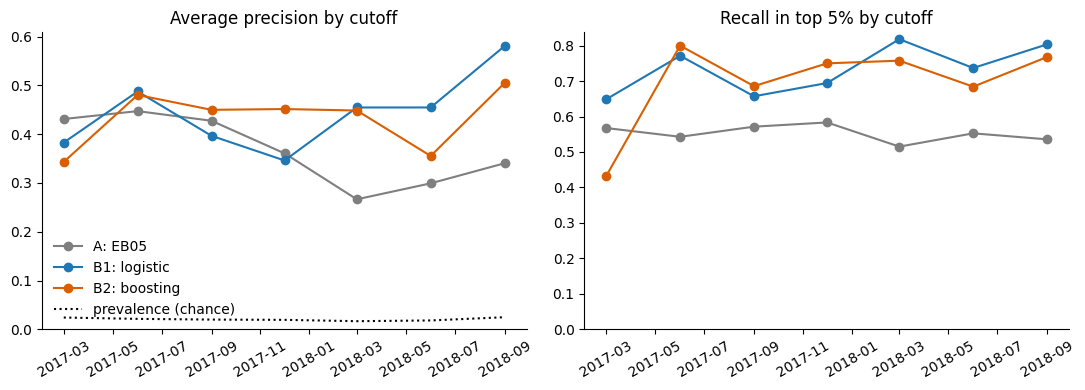

In [57]:
def per_cut(d, s, pct=0.05):
    rows = []
    for t, x in d.groupby("cutoff"):
        k = max(1, int(round(pct * len(x))))
        rows.append((t, average_precision_score(x.y, x[s]),
                     x.sort_values(s, ascending=False).y.head(k).sum() / x.y.sum(), x.y.mean()))
    return pd.DataFrame(rows, columns=["cutoff", "ap", "rec5", "prev"]).set_index("cutoff")

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for name, s in {"A: EB05": "EB05", "B1: logistic": "p_lr", "B2: boosting": "p_gb"}.items():
    pc = per_cut(test, s)
    ax[0].plot(pc.index, pc.ap, marker="o", color=COL[name], label=name)
    ax[1].plot(pc.index, pc.rec5, marker="o", color=COL[name], label=name)
ax[0].plot(pc.index, pc.prev, ls=":", color="k", label="prevalence (chance)")
ax[0].set_title("Average precision by cutoff"); ax[1].set_title("Recall in top 5% by cutoff")
ax[0].legend(frameon=False)
for a in ax: a.tick_params(axis="x", rotation=30); a.set_ylim(0, None)
save("01_per_cutoff")

### Plot 2: Pooled results with 95% intervals

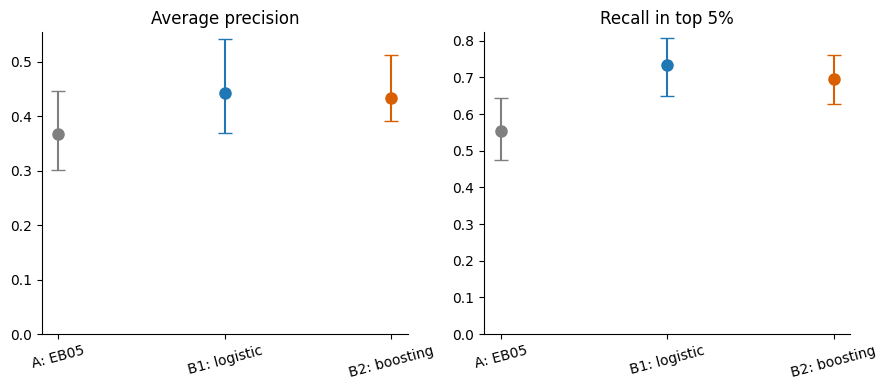

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for j, metric in enumerate(["Average precision", "Recall in top 5%"]):
    for i, k in enumerate(scores):
        lo, hi = np.percentile(boot[k][:, j], [2.5, 97.5])
        ax[j].errorbar(i, base[k][j], yerr=[[base[k][j] - lo], [hi - base[k][j]]],
                       fmt="o", ms=8, capsize=5, color=COL[k])
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(list(scores), rotation=15)
    ax[j].set_title(metric); ax[j].set_ylim(0, None)
save("02_pooled")

### Plot 3: Gain over EB05, with and without 2018-09

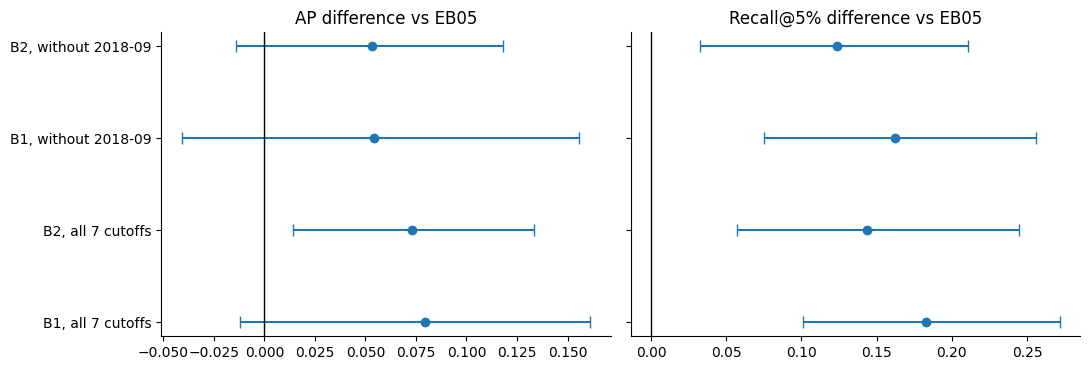

In [59]:
items = []
for lab_, bt, key in [("all 7 cutoffs", boot, {"B1": "B1: logistic", "B2": "B2: boosting", "A": "A: EB05"}),
                      ("without 2018-09", boot2, {"B1": "p_lr", "B2": "p_gb", "A": "EB05"})]:
    for m in ["B1", "B2"]:
        d = bt[key[m]] - bt[key["A"]]
        items.append((f"{m}, {lab_}", d.mean(0), np.percentile(d, [2.5, 97.5], axis=0)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for j, metric in enumerate(["AP difference vs EB05", "Recall@5% difference vs EB05"]):
    for i, (lbl, mean, ci) in enumerate(items):
        ax[j].errorbar(mean[j], i, xerr=[[mean[j] - ci[0, j]], [ci[1, j] - mean[j]]], fmt="o", capsize=4, color="#1f77b4")
    ax[j].axvline(0, color="k", lw=1); ax[j].set_title(metric)
    ax[j].set_yticks(range(len(items))); ax[j].set_yticklabels([x[0] for x in items])
save("03_gain_over_eb05")

### Plot 4: Lead time

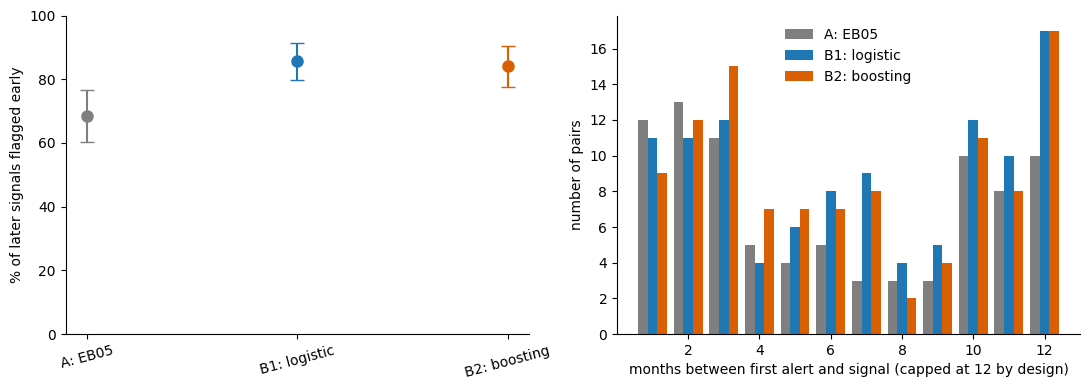

In [60]:
S = ["EB05", "p_lr", "p_gb"]; nm = {"EB05": "A: EB05", "p_lr": "B1: logistic", "p_gb": "B2: boosting"}
bpos = pp[pp.pos]
boot_lead = res                                  # your bootstrap table from the lead-time cell

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, s in enumerate(S):
    est = 100 * bpos["flag_" + s].mean()
    lo, hi = np.percentile(boot_lead["pct_" + s], [2.5, 97.5])
    ax[0].errorbar(i, est, yerr=[[est - lo], [hi - est]], fmt="o", ms=8, capsize=5, color=COL[nm[s]])
ax[0].set_xticks(range(3)); ax[0].set_xticklabels([nm[s] for s in S], rotation=15)
ax[0].set_ylabel("% of later signals flagged early"); ax[0].set_ylim(0, 100)

w = 0.27
for i, s in enumerate(S):
    cnt = bpos["lead_" + s].dropna().value_counts().reindex(range(1, 13), fill_value=0)
    ax[1].bar(np.arange(1, 13) + (i - 1) * w, cnt.values, w, color=COL[nm[s]], label=nm[s])
ax[1].set_xlabel("months between first alert and signal (capped at 12 by design)")
ax[1].set_ylabel("number of pairs"); ax[1].legend(frameon=False)
save("04_lead_time")

### Plot 5: Ablation, level and age versus growth

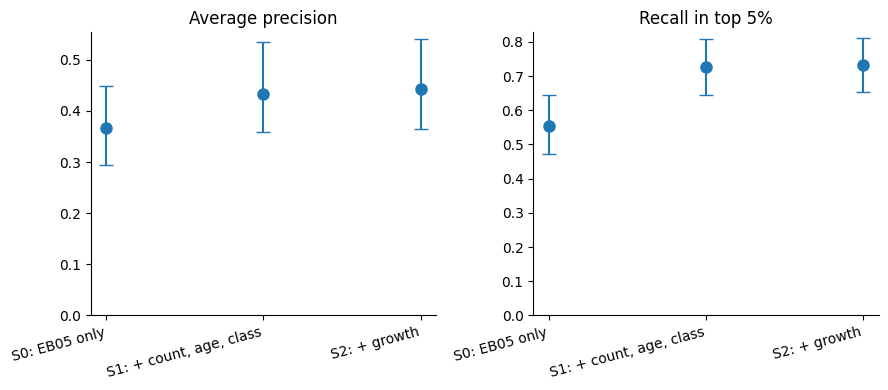

In [61]:
sets_ab = {"S0: EB05 only": "s0", "S1: + count, age, class": "s1", "S2: + growth": "s2"}
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for j, metric in enumerate(["Average precision", "Recall in top 5%"]):
    for i, (lbl, k) in enumerate(sets_ab.items()):
        est = pooled(ab, k)[j]
        lo, hi = np.percentile(bs[k][:, j], [2.5, 97.5])
        ax[j].errorbar(i, est, yerr=[[est - lo], [hi - est]], fmt="o", ms=8, capsize=5, color="#1f77b4")
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(list(sets_ab), rotation=15, ha="right")
    ax[j].set_title(metric); ax[j].set_ylim(0, None)
save("05_ablation")

### Plot 6: Which features the logistic model uses

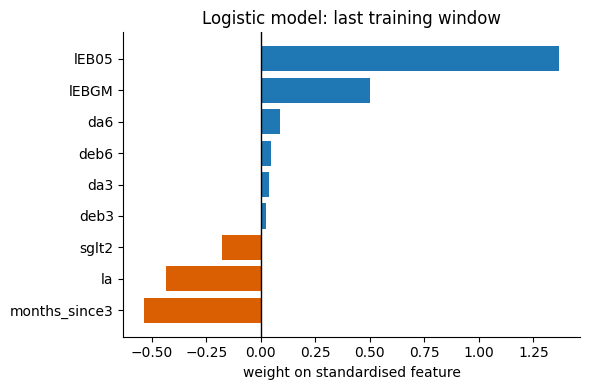

In [62]:

tr = panel[panel.cutoff <= pd.Timestamp("2018-09-01") - pd.DateOffset(months=GAP)]
m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  LogisticRegression(C=0.5, max_iter=2000)).fit(tr[FEATS], tr.y)
coef = pd.Series(m[-1].coef_[0], index=FEATS).sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(coef.index, coef.values, color=np.where(coef.values >= 0, "#1f77b4", "#d95f02"))
ax.axvline(0, color="k", lw=1); ax.set_xlabel("weight on standardised feature")
ax.set_title("Logistic model: last training window")
save("06_coefficients")

### Plot 7: Two case studies, a gradual signal versus abrupt ones

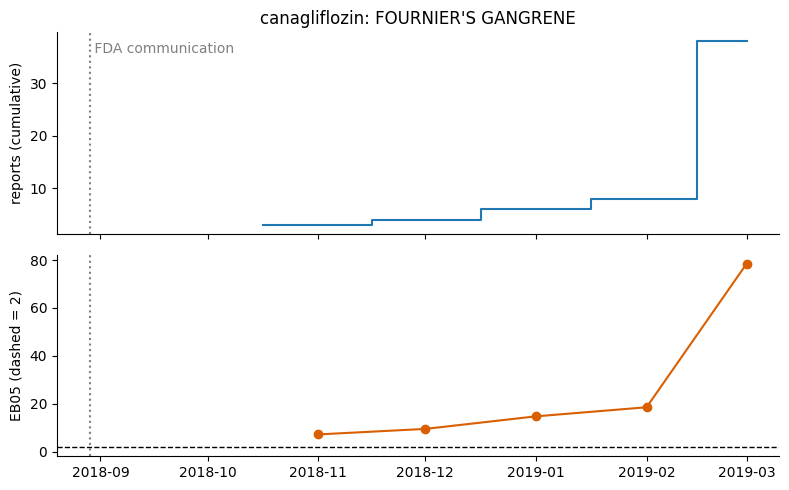

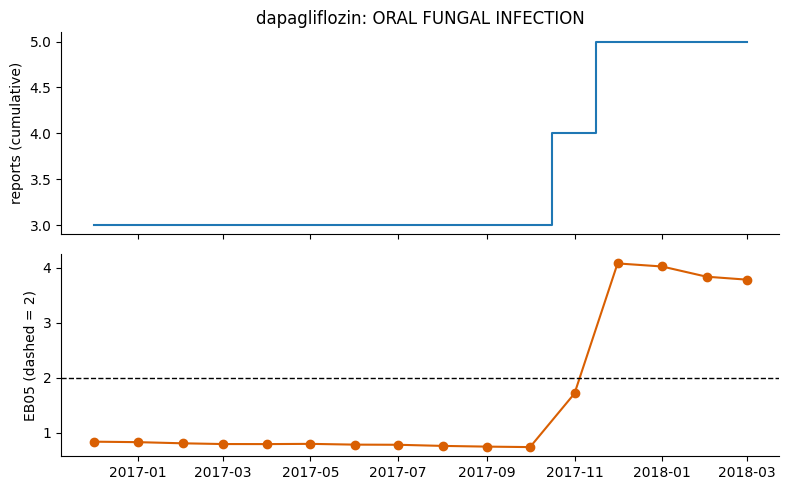

In [63]:
def plot_pair(pair, start, end, vline=None, vlabel=None):
    h = g.xs(pair, level="pair").reset_index()
    h = h[(h.m >= start) & (h.m <= end)]
    fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
    ax[0].step(h.m, h.a, where="mid", color="#1f77b4"); ax[0].set_ylabel("reports (cumulative)")
    ax[1].plot(h.m, h.EB05, marker="o", color="#d95f02"); ax[1].axhline(2, color="k", ls="--", lw=1)
    ax[1].set_ylabel("EB05 (dashed = 2)")
    for a_ in ax:
        if vline: a_.axvline(pd.Timestamp(vline), color="grey", ls=":")
    if vline: ax[0].text(pd.Timestamp(vline), ax[0].get_ylim()[1] * 0.9, " " + vlabel, color="grey")
    ax[0].set_title(f"{pair[0]}: {pair[1]}")
    return fig

plot_pair(("canagliflozin", "FOURNIER'S GANGRENE"), "2018-01-01", "2019-03-01", "2018-08-29", "FDA communication")
save("07a_fourniers")
plot_pair(("dapagliflozin", "ORAL FUNGAL INFECTION"), "2016-12-01", "2018-03-01")
save("07b_oral_fungal")

### Plot 8: Onsets per quarter, burn-in choice

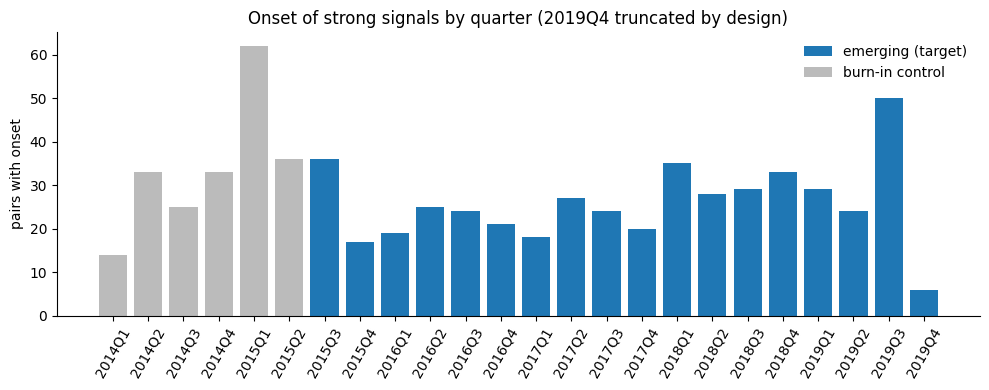

In [64]:
lab3 = make_labels(g, months, 3, burn_in_end="2015-06-01")
lab3["q"] = lab3.onset_run.dt.to_period("Q")
tab = lab3[lab3.status.isin(["emerging", "control_burn_in"])].groupby(["q", "status"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(tab))
ax.bar(x, tab.get("emerging", 0), color="#1f77b4", label="emerging (target)")
ax.bar(x, tab.get("control_burn_in", 0), bottom=tab.get("emerging", 0), color="#bbbbbb", label="burn-in control")
ax.set_xticks(x); ax.set_xticklabels(tab.index.astype(str), rotation=60)
ax.set_ylabel("pairs with onset"); ax.legend(frameon=False)
ax.set_title("Onset of strong signals by quarter (2019Q4 truncated by design)")
save("08_onsets")

## Time series forecast

In [ ]:
## Step 1: Wide tables and the forecasting function

# one row per pair, one column per month (cumulative reports a, cumulative expected E)
e_long = con.sql("SELECT ingredient, pt, m, E FROM fc_pair_month_e").df()
e_long["m"] = pd.to_datetime(e_long.m)
e_long["pid"] = [pid_map.get(p_) for p_ in zip(e_long.ingredient, e_long.pt)]
E_w = e_long.pivot(index="pid", columns="m", values="E")
A_w = a_s.unstack("m")                          # a_s is indexed by (pid, m)

HF, W = 12, 12                                  # forecast horizon, history window (months)

def forecast_total(wide, pids, t, method):
    """Cumulative value at t + HF, using only data up to t."""
    cols = pd.date_range(t - pd.DateOffset(months=W), t, freq="MS")     # 13 cumulative points
    cum = wide.loc[pids, cols].values
    inc = np.clip(np.diff(cum, axis=1), 0, None)                         # 12 monthly increments
    if method == "flat":
        f = np.repeat(inc.mean(axis=1, keepdims=True), HF, axis=1)
    else:                                                                # "trend": least-squares line
        x = np.arange(W); xm = x.mean()
        slope = ((x - xm) * (inc - inc.mean(1, keepdims=True))).sum(1) / ((x - xm) ** 2).sum()
        icpt = inc.mean(1) - slope * xm
        f = np.clip(icpt[:, None] + slope[:, None] * np.arange(W, W + HF), 0, None)
    return cum[:, -1] + f.sum(axis=1)

In [66]:
## Step 2: Add the forecasts to the panel

def add_forecasts(panel, method):
    out = panel.copy()
    a_hat, E_hat = np.zeros(len(out)), np.zeros(len(out))
    for t, ix in out.groupby("cutoff").indices.items():       # ix = row positions for this cutoff
        pids = out.pid.values[ix]
        a_hat[ix] = forecast_total(A_w, pids, t, method)
        E_hat[ix] = forecast_total(E_w, pids, t, method)
    E_hat = np.maximum(E_hat, 1e-9)
    out["a_hat"], out["E_hat"] = a_hat, E_hat
    out["EB05_hat"] = [eb(a, E)[1] for a, E in zip(a_hat, E_hat)]
    out["lEB05_hat"] = np.log1p(out.EB05_hat)
    out["gr_hat"] = np.log(out.a_hat) - out.la               # forecast growth in reports
    out["deb_hat"] = out.EB05_hat - out.EB05                 # forecast change in EB05
    return out

panel_flat  = add_forecasts(panel, "flat")
panel_trend = add_forecasts(panel, "trend")

In [67]:
## Step 3: How accurate are the forecasts?
rows = []
for name, pf in {"no change": None, "flat": panel_flat, "trend": panel_trend}.items():
    errs = []
    for t, x in panel.groupby("cutoff"):
        t12 = t + pd.DateOffset(months=12)
        true_a = A_w.loc[x.pid.values, t12].values
        if pf is None:
            pred = x.la.pipe(np.exp).values                    # a_t
        else:
            pred = pf.loc[x.index, "a_hat"].values
        errs.append(np.abs(np.log1p(pred) - np.log1p(true_a)))
    rows.append((name, np.concatenate(errs).mean()))
print(pd.DataFrame(rows, columns=["method", "mean abs error (log scale)"]).round(3))

      method  mean abs error (log scale)
0  no change                       0.284
1       flat                       0.197
2      trend                       0.327


In [68]:
## Step 4: Does the forecast predict emergence?

cut_test = pd.Timestamp("2017-03-01")
tf, tt = (p[p.cutoff >= cut_test] for p in (panel_flat, panel_trend))
tb = panel[panel.cutoff >= cut_test]

print("A  EB05 now      ", np.round(pooled(tb, "EB05"), 3))
print("C1 forecast flat ", np.round(pooled(tf, "EB05_hat"), 3))
print("C2 forecast trend", np.round(pooled(tt, "EB05_hat"), 3))

A  EB05 now       [0.368 0.553]
C1 forecast flat  [0.383 0.699]
C2 forecast trend [0.309 0.592]


In [69]:
## Step 5: Combine forecast with the other features (Arm D)
def walk_df(df, feats):
    parts = []
    for t in test_cuts:
        tr = df[df.cutoff <= t - pd.DateOffset(months=GAP)]
        te = df[df.cutoff == t].copy()
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.5, max_iter=2000)).fit(tr[feats], tr.y)
        te["p"] = m.predict_proba(te[feats])[:, 1]
        parts.append(te)
    return pd.concat(parts)

S1 = ["lEB05", "lEBGM", "la", "months_since3", "sglt2"]
FC = ["lEB05_hat", "gr_hat", "deb_hat"]
wS1 = walk_df(panel_trend, S1)
wD  = walk_df(panel_trend, S1 + FC)

print("S1 (level + age)        ", np.round(pooled(wS1, "p"), 3))
print("D  (S1 + forecast trend)", np.round(pooled(wD, "p"), 3))


S1 (level + age)         [0.434 0.726]
D  (S1 + forecast trend) [0.423 0.724]


In [70]:
## Step 6: Paired bootstrap
d_ = wS1[["pid", "cutoff", "y"]].copy()
d_["A"] = tb.set_index(wS1.index).EB05 if False else wS1.EB05      # EB05 now
d_["C2"], d_["S1"], d_["D"] = tt.EB05_hat.values, wS1.p.values, wD.p.values

rng = np.random.default_rng(0); pids_ = d_.pid.unique()
bb = {k: [] for k in ["A", "C2", "S1", "D"]}
for _ in range(500):
    x = d_.merge(pd.DataFrame({"pid": rng.choice(pids_, len(pids_), replace=True)}), on="pid")
    for k in bb: bb[k].append(pooled(x, k))
bb = {k: np.array(v) for k, v in bb.items()}

for name, a, b in [("C2 - A (forecast vs EB05 now)", "C2", "A"),
                   ("D - S1 (forecast features added)", "D", "S1")]:
    d = bb[a] - bb[b]
    print(name, "| AP", np.percentile(d[:, 0], [2.5, 97.5]).round(3),
          "| recall@5%", np.percentile(d[:, 1], [2.5, 97.5]).round(3))

C2 - A (forecast vs EB05 now) | AP [-0.135  0.042] | recall@5% [-0.058  0.124]
D - S1 (forecast features added) | AP [-0.027  0.006] | recall@5% [-0.048  0.025]


#### Close the DB Connection

In [ ]:
con.close()

# Explicitly close any ambient DuckDB connections
try:
    duckdb.close()
    print("✓ Closed ambient DuckDB connection.")
except Exception as e:
    print(f"Notice: {e}")